In [1]:
%%writefile /home/jovyan/work/spark_common.py
import os
from pyspark.sql import SparkSession, types as T

DATA = os.environ.get("DATA_DIR", "/home/jovyan/work/data")
PARQUET = os.environ.get("PARQUET_DIR", "/home/jovyan/work/parquet")

def get_spark(app="ecommerce"):
    spark = (SparkSession.builder.master("local[2]").appName(app)
             .config("spark.driver.memory", "2g")
             .config("spark.sql.shuffle.partitions", "8")
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    return spark

S = T.StringType()
geo = T.StructType([T.StructField(n, S) for n in ["city", "state", "country", "ip_address"]])
device = T.StructType([T.StructField(n, S) for n in ["type", "os", "browser"]])
page_view = T.StructType([T.StructField("timestamp", S), T.StructField("page_type", S),
                          T.StructField("product_id", S), T.StructField("category_id", S),
                          T.StructField("view_duration", T.LongType())])
cart = T.MapType(S, T.StructType([T.StructField("quantity", T.LongType()),
                                  T.StructField("price", T.DoubleType())]))

# Explicit schemas: Spark skips the extra pass over the 188 MB files that inference would need.
SESSIONS_SCHEMA = T.StructType([
    T.StructField("session_id", S), T.StructField("user_id", S),
    T.StructField("start_time", S), T.StructField("end_time", S),
    T.StructField("duration_seconds", T.LongType()), T.StructField("geo_data", geo),
    T.StructField("device_profile", device), T.StructField("viewed_products", T.ArrayType(S)),
    T.StructField("page_views", T.ArrayType(page_view)), T.StructField("cart_contents", cart),
    T.StructField("conversion_status", S), T.StructField("referrer", S)])

Writing /home/jovyan/work/spark_common.py


In [2]:
cd /d "D:\AUCA\Big Data Analytics\Final_Project"
echo parquet/>> .gitignore
type .gitignore

<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_13304/3696266292.py:1: SyntaxWarning: invalid escape sequence '\A'
  cd /d "D:\AUCA\Big Data Analytics\Final_Project"


SyntaxError: invalid syntax (3696266292.py, line 1)

In [3]:
!ls /home/jovyan/work

 00_connection_test.ipynb		  docker-compose.yml
 02_hbase.ipynb				  fix_generator.py
 03_spark.ipynb				  hbase_common.py
'AUCA Final Project Oct 2026.pdf'	  hbase_queries.py
 Screenshots				  jupyter
 __pycache__				  load_hbase.py
 data					  load_mongo.py
 dataset_generator.py			  mongo_pipelines.py
 dataset_generator_notebook_backup.json	  spark_common.py


In [4]:
%%writefile /home/jovyan/work/spark_01_ingest.py
import os, sys, time
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from pyspark.sql import functions as F
from spark_common import get_spark, DATA, PARQUET, SESSIONS_SCHEMA

spark = get_spark("01_ingest")
t0 = time.time()

# ---- sessions: JSON array files -> typed columns -> Parquet ----
raw = spark.read.schema(SESSIONS_SCHEMA).option("multiLine", True).json(f"{DATA}/sessions_*.json")
sessions = (raw.withColumn("start_ts", F.col("start_time").cast("timestamp"))
               .withColumn("end_ts", F.col("end_time").cast("timestamp"))
               .withColumn("n_pages", F.size("page_views"))
               .withColumn("cart_items", F.size("cart_contents")))
sessions.write.mode("overwrite").parquet(f"{PARQUET}/sessions_raw")
print(f"sessions JSON -> Parquet: {time.time() - t0:.0f}s")

# ---- the small files ----
for name in ["users", "products", "categories", "transactions"]:
    spark.read.option("multiLine", True).json(f"{DATA}/{name}.json").write.mode("overwrite").parquet(f"{PARQUET}/{name}_raw")

s = spark.read.parquet(f"{PARQUET}/sessions_raw")
u, p, c, t = (spark.read.parquet(f"{PARQUET}/{n}_raw") for n in ["users", "products", "categories", "transactions"])
print("\n=== row counts ===")
print(f"sessions {s.count():,} | users {u.count():,} | products {p.count():,} | categories {c.count():,} | transactions {t.count():,}")
print("distinct session_id:", f"{s.select('session_id').distinct().count():,}")
print("\n=== data-quality profile ===")
print("null start/end timestamps:", s.filter("start_ts is null or end_ts is null").count())
print("end_time != start_time + duration:", s.filter(F.col("end_ts").cast("long") - F.col("start_ts").cast("long") != F.col("duration_seconds")).count())
print("status:", {r[0]: r[1] for r in s.groupBy("conversion_status").count().collect()})
pv = s.select("session_id", "cart_items", F.explode("page_views").alias("p"))
n_pv = pv.count()
print(f"page views: {n_pv:,} | zero-duration: {pv.filter('p.view_duration = 0').count():,}")
empty_cart = pv.filter("p.page_type in ('cart','checkout','confirmation') and cart_items = 0").select("session_id").distinct().count()
print(f"sessions with cart/checkout/confirmation page but EMPTY cart: {empty_cart:,}")
print("\n=== page-flow funnel (sessions reaching each page type) ===")
reach = {r[0]: r[1] for r in pv.select("session_id", "p.page_type").distinct().groupBy("page_type").count().collect()}
for k in ["home", "search", "category_listing", "product_detail", "cart", "checkout", "confirmation"]:
    print(f"  {k:17s} {reach.get(k, 0):>8,}")
print("\n=== referential integrity ===")
lt = t.filter("session_id is not null")
print("converted sessions without a transaction:", s.filter("conversion_status='converted'").join(lt, "session_id", "left_anti").count())
print("linked transactions whose session is missing:", lt.join(s, "session_id", "left_anti").count())
items = t.select(F.explode("items").alias("i")).select("i.product_id")
print("transaction items on inactive products:", items.join(p.filter("is_active = false").select("product_id"), "product_id").count())
print(f"\ntotal {time.time() - t0:.0f}s")

Writing /home/jovyan/work/spark_01_ingest.py


In [5]:
!python /home/jovyan/work/spark_01_ingest.py

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/05 11:35:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
sessions JSON -> Parquet: 62s

=== row counts ===
sessions 200,000 | users 10,000 | products 5,000 | categories 25 | transactions 100,000
distinct session_id: 200,000

=== data-quality profile ===
null start/end timestamps: 0
end_time != start_time + duration: 0
status: {'converted': 40488, 'abandoned': 89436, 'browsed': 70076}
page views: 1,997,108 | zero-duration: 11,362
sessions with cart/checkout/confirmation page but EMPTY cart: 43,754

=== page-flow funnel (sessions reaching each page type) ===
  home               154,930
  search             149,759
  category_listing   176,851
  product_detail     197,462
  cart               135

In [6]:
%%writefile /home/jovyan/work/spark_02_clean.py
import os, sys, time
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import pandas as pd
from pyspark.sql import functions as F
from spark_common import get_spark, PARQUET

RESULTS = os.environ.get("RESULTS_DIR", "/home/jovyan/work/results")
os.makedirs(RESULTS, exist_ok=True)
spark = get_spark("02_clean")
t0 = time.time()
report = []                                   # (dataset, check, rows affected, total rows, action)
def rep(ds, check, n, total, action):
    report.append((ds, check, int(n), int(total), action))

# ============================== SESSIONS ==============================
s = spark.read.parquet(f"{PARQUET}/sessions_raw")
n_in = s.count()
s = s.dropDuplicates(["session_id"])                                   # rule 1: no duplicate sessions
rep("sessions", "duplicate session_id removed", n_in - s.count(), n_in, "dropped")

pt = lambda name: F.exists("page_views", lambda x: x.page_type == name)
sc = (s.withColumn("user_id", F.trim("user_id"))                      # rule 2: standardise text formats
        .withColumn("country", F.upper(F.trim("geo_data.country")))
        .withColumn("state", F.upper(F.trim("geo_data.state")))
        .withColumn("city", F.trim("geo_data.city"))
        .withColumn("device", F.lower(F.trim("device_profile.type")))
        .withColumn("os", F.trim("device_profile.os"))
        .withColumn("browser", F.trim("device_profile.browser"))
        .withColumn("referrer", F.lower(F.trim("referrer")))
        .withColumn("session_date", F.to_date("start_ts"))
        .withColumn("start_hour", F.hour("start_ts"))
        .withColumn("day_of_week", F.date_format("start_ts", "E"))
        # rule 3: page-flow facts used by the funnel
        .withColumn("has_product_detail", pt("product_detail"))
        .withColumn("has_cart_page", pt("cart"))
        .withColumn("has_checkout_page", pt("checkout"))
        .withColumn("has_confirmation_page", pt("confirmation"))
        .withColumn("n_zero_dur_views", F.size(F.filter("page_views", lambda x: x.view_duration == 0)))
        # rule 4: flag (do not delete) generator inconsistencies
        .withColumn("flag_empty_cart_flow", (F.col("has_cart_page") | F.col("has_checkout_page") | F.col("has_confirmation_page")) & (F.col("cart_items") == 0))
        .withColumn("flag_confirm_no_purchase", F.col("has_confirmation_page") & (F.col("conversion_status") != "converted"))
        # clean funnel stages: a stage only counts if the previous one is real
        .withColumn("f_viewed_product", F.col("has_product_detail"))
        .withColumn("f_added_to_cart", F.col("cart_items") > 0)
        .withColumn("f_reached_checkout", F.col("has_checkout_page") & (F.col("cart_items") > 0))
        .withColumn("f_converted", F.col("conversion_status") == "converted")
        .drop("geo_data", "device_profile", "start_time", "end_time"))
a = sc.agg(F.count("*").alias("n"),
           F.sum((F.col("n_zero_dur_views") > 0).cast("int")).alias("zero_sessions"),
           F.sum("n_zero_dur_views").alias("zero_views"),
           F.sum(F.col("flag_empty_cart_flow").cast("int")).alias("empty_cart"),
           F.sum(F.col("flag_confirm_no_purchase").cast("int")).alias("confirm_no_buy"),
           F.sum(F.col("start_ts").isNull().cast("int")).alias("null_ts"),
           F.sum(F.col("user_id").isNull().cast("int")).alias("null_user"),
           F.sum(F.col("referrer").isNull().cast("int")).alias("null_ref")).collect()[0]
rep("sessions", "null timestamps / user_id / referrer", a.null_ts + a.null_user + a.null_ref, a.n, "none found")
rep("sessions", "sessions containing zero-duration page views", a.zero_sessions, a.n, f"flagged ({a.zero_views:,} views counted in n_zero_dur_views)")
rep("sessions", "cart/checkout/confirmation page with an empty cart", a.empty_cart, a.n, "flagged flag_empty_cart_flow")
rep("sessions", "confirmation page without a purchase", a.confirm_no_buy, a.n, "flagged flag_confirm_no_purchase")
sc.write.mode("overwrite").parquet(f"{PARQUET}/sessions_clean")

# ============================== TRANSACTIONS ==============================
t = spark.read.parquet(f"{PARQUET}/transactions_raw")
n_in = t.count()
t = t.dropDuplicates(["transaction_id"])
rep("transactions", "duplicate transaction_id removed", n_in - t.count(), n_in, "dropped")
tc = (t.withColumn("txn_ts", F.col("timestamp").cast("timestamp"))
        .withColumn("txn_date", F.to_date("txn_ts"))
        .withColumn("txn_month", F.date_format("txn_ts", "yyyy-MM"))
        .withColumn("n_items", F.size("items"))
        .withColumn("units", F.aggregate("items", F.lit(0).cast("long"), lambda acc, x: acc + x.quantity))
        .withColumn("items_sum", F.aggregate("items", F.lit(0.0), lambda acc, x: acc + x.subtotal))
        .withColumn("is_linked", F.col("session_id").isNotNull())
        .withColumn("flag_subtotal_mismatch", F.abs(F.col("items_sum") - F.col("subtotal")) > 0.011)
        .withColumn("flag_total_mismatch", F.abs(F.col("subtotal") - F.col("discount") - F.col("total")) > 0.011)
        .drop("timestamp"))
b = tc.agg(F.count("*").alias("n"), F.sum((~F.col("is_linked")).cast("int")).alias("unlinked"),
           F.sum(F.col("flag_subtotal_mismatch").cast("int")).alias("sub_bad"),
           F.sum(F.col("flag_total_mismatch").cast("int")).alias("tot_bad"),
           F.sum((F.col("n_items") == 0).cast("int")).alias("empty"),
           F.sum((F.col("total") <= 0).cast("int")).alias("nonpos")).collect()[0]
rep("transactions", "subtotal differs from sum of items", b.sub_bad, b.n, "none found" if b.sub_bad == 0 else "flagged")
rep("transactions", "total != subtotal - discount", b.tot_bad, b.n, "none found" if b.tot_bad == 0 else "flagged")
rep("transactions", "no items / non-positive total", b.empty + b.nonpos, b.n, "none found")
rep("transactions", "not linked to a session (session_id null)", b.unlinked, b.n, "kept, is_linked=false (excluded from funnel)")
tc.write.mode("overwrite").parquet(f"{PARQUET}/transactions_clean")

# ============================== USERS & PRODUCTS ==============================
u = spark.read.parquet(f"{PARQUET}/users_raw")
uc = (u.withColumn("registered", F.col("registration_date").cast("timestamp"))
       .withColumn("last_active_ts", F.col("last_active").cast("timestamp"))
       .withColumn("registration_month", F.date_format("registered", "yyyy-MM"))
       .withColumn("country", F.upper(F.trim("geo_data.country"))).withColumn("state", F.upper(F.trim("geo_data.state")))
       .withColumn("city", F.trim("geo_data.city")).drop("geo_data", "registration_date", "last_active"))
bad_u = uc.filter(F.col("last_active_ts") < F.col("registered")).count()
rep("users", "last_active earlier than registration", bad_u, uc.count(), "none found" if bad_u == 0 else "flagged")
uc.write.mode("overwrite").parquet(f"{PARQUET}/users_clean")

p = spark.read.parquet(f"{PARQUET}/products_raw")
pc = (p.withColumn("created", F.col("creation_date").cast("timestamp"))
       .withColumn("is_sellable", F.col("is_active") & (F.col("current_stock") > 0)).drop("creation_date"))
rep("products", "inactive products", pc.filter(~F.col("is_active")).count(), pc.count(), "kept, is_sellable=false")
rep("products", "zero stock", pc.filter(F.col("current_stock") == 0).count(), pc.count(), "kept, is_sellable=false")
pc.write.mode("overwrite").parquet(f"{PARQUET}/products_clean")

# ============================== REPORT ==============================
df = pd.DataFrame(report, columns=["dataset", "check", "rows", "of_total", "action"])
df["pct"] = (100 * df["rows"] / df["of_total"]).round(2)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 70)
print(df[["dataset", "check", "rows", "of_total", "pct", "action"]].to_string(index=False))
df.to_csv(f"{RESULTS}/cleaning_report.csv", index=False)
print(f"\ntotal {time.time() - t0:.0f}s | clean Parquet written to {PARQUET}")

Writing /home/jovyan/work/spark_02_clean.py


In [7]:
!python /home/jovyan/work/spark_02_clean.py

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/05 11:43:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
     dataset                                              check  rows  of_total   pct                                             action
    sessions                       duplicate session_id removed     0    200000  0.00                                            dropped
    sessions               null timestamps / user_id / referrer     0    200000  0.00                                         none found
    sessions       sessions containing zero-duration page views  9814    200000  4.91 flagged (11,362 views counted in n_zero_dur_views)
    sessions cart/checkout/confirmation page with an empty cart 43754    200000 21.88             

In [8]:
%%writefile /home/jovyan/work/spark_03_cohort.py
import os, sys, time
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import pandas as pd
from spark_common import get_spark, PARQUET

RESULTS = os.environ.get("RESULTS_DIR", "/home/jovyan/work/results")
os.makedirs(RESULTS, exist_ok=True)
spark = get_spark("03_cohort")
t0 = time.time()

spark.read.parquet(f"{PARQUET}/users_clean").createOrReplaceTempView("users")
spark.read.parquet(f"{PARQUET}/transactions_clean").createOrReplaceTempView("txns")

# Cohort = month the user registered. For every cohort and purchase month we measure how many users bought,
# how many orders, and how much revenue. Months at the edge of the data are partial (Aug starts on the 6th,
# Nov stops on the 4th), so revenue is also normalised per observed day.
cohort_sql = """
WITH cohort AS (                                   -- size of each registration cohort
    SELECT registration_month AS cohort, COUNT(*) AS cohort_size
    FROM users GROUP BY registration_month),
days AS (                                          -- observed days per purchase month
    SELECT txn_month AS month, COUNT(DISTINCT txn_date) AS days
    FROM txns GROUP BY txn_month),
agg AS (                                           -- cohort x month activity
    SELECT u.registration_month AS cohort, t.txn_month AS month,
           COUNT(DISTINCT t.user_id) AS active_buyers, COUNT(*) AS orders, SUM(t.total) AS revenue
    FROM txns t JOIN users u ON t.user_id = u.user_id
    GROUP BY u.registration_month, t.txn_month)
SELECT a.cohort, a.month, c.cohort_size, a.active_buyers,
       ROUND(100.0 * a.active_buyers / c.cohort_size, 1)                       AS buyer_pct,
       a.orders, ROUND(a.revenue, 2)                                           AS revenue,
       ROUND(a.revenue / c.cohort_size, 2)                                     AS revenue_per_user,
       ROUND(a.revenue / c.cohort_size / d.days, 2)                            AS revenue_per_user_per_day,
       ROUND(SUM(a.revenue) OVER (PARTITION BY a.cohort ORDER BY a.month)
             / c.cohort_size, 2)                                               AS cumulative_revenue_per_user
FROM agg a JOIN cohort c ON a.cohort = c.cohort JOIN days d ON a.month = d.month
ORDER BY a.cohort, a.month
"""
df = spark.sql(cohort_sql).toPandas()
df.to_csv(f"{RESULTS}/cohort_analysis.csv", index=False)

pd.set_option("display.width", 200)
sizes = df.drop_duplicates("cohort").set_index("cohort")["cohort_size"].rename("users")
print("=== cohort sizes (users by registration month) ===")
print(sizes.to_string())
print("\n=== % of cohort that bought, by purchase month ===")
print(df.pivot(index="cohort", columns="month", values="buyer_pct").to_string())
print("\n=== revenue per user per day, by purchase month ===")
print(df.pivot(index="cohort", columns="month", values="revenue_per_user_per_day").to_string())
print("\n=== cumulative revenue per user at the end of the data ===")
print(df.groupby("cohort")["cumulative_revenue_per_user"].max().to_string())
spread = df.groupby("cohort")["revenue_per_user_per_day"].mean()
print(f"\nmean daily revenue per user: min {spread.min():.2f} | max {spread.max():.2f} | spread {100*(spread.max()/spread.min()-1):.1f}%")
print(f"total {time.time() - t0:.0f}s | saved {RESULTS}/cohort_analysis.csv")

Writing /home/jovyan/work/spark_03_cohort.py


In [9]:
!python /home/jovyan/work/spark_03_cohort.py

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/05 11:49:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
=== cohort sizes (users by registration month) ===
cohort
2026-02    1221
2026-03    1731
2026-04    1669
2026-05    1726
2026-06    1617
2026-07    1734
2026-08     302

=== % of cohort that bought, by purchase month ===
month   2026-08 2026-09 2026-10 2026-11
cohort                                 
2026-02    94.6    96.6    97.6    31.0
2026-03    94.7    96.5    97.1    33.3
2026-04    93.6    96.6    96.8    30.8
2026-05    94.1    95.2    96.6    32.7
2026-06    93.6    96.7    96.7    30.8
2026-07    93.9    96.9    96.4    32.6
2026-08    96.0    96.0    97.0    35.1

=== revenue per user per day, by purchase month ===
month    20

In [10]:
%%writefile /home/jovyan/work/spark_04_funnel.py
import os, sys, time
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import pandas as pd
import pymongo
from pyspark.sql import types as T
import hbase_common as hc
from spark_common import get_spark

RESULTS = os.environ.get("RESULTS_DIR", "/home/jovyan/work/results")
MONGO_URI = os.environ.get("MONGO_URI", "mongodb://mongo:27017")

HB_SCHEMA = T.StructType([
    T.StructField("session_id", T.StringType()), T.StructField("user_id", T.StringType()),
    T.StructField("device", T.StringType()), T.StructField("referrer", T.StringType()),
    T.StructField("country", T.StringType()), T.StructField("status", T.StringType()),
    T.StructField("viewed_product", T.BooleanType()), T.StructField("cart_items", T.IntegerType()),
    T.StructField("checkout_page", T.BooleanType())])
MG_SCHEMA = T.StructType([
    T.StructField("txn_id", T.StringType()), T.StructField("session_id", T.StringType()),
    T.StructField("user_id", T.StringType()), T.StructField("revenue", T.DoubleType()),
    T.StructField("units", T.LongType())])

def read_hbase_sessions():
    """HBase: one row per session. We read only the columns the funnel needs and reduce the
    page-view columns to yes/no flags while streaming, so memory stays small."""
    table = hc.connect().table(hc.SESSIONS)
    cols = [b"meta:session_id", b"meta:user_id", b"meta:device", b"meta:referrer", b"meta:country",
            b"meta:status", b"pv", b"cart"]
    rows = []
    for _, d in table.scan(columns=cols, batch_size=2000):
        page_types = {v.split(b"|", 2)[1] for k, v in d.items() if k.startswith(b"pv:")}
        rows.append((d[b"meta:session_id"].decode(), d[b"meta:user_id"].decode(),
                     d[b"meta:device"].decode(), d[b"meta:referrer"].decode(),
                     d[b"meta:country"].decode(), d[b"meta:status"].decode(),
                     b"product_detail" in page_types,
                     sum(1 for k in d if k.startswith(b"cart:")),
                     b"checkout" in page_types))
    return rows

def read_mongo_txns():
    """MongoDB: only transactions that belong to a session (session_id not null)."""
    coll = pymongo.MongoClient(MONGO_URI)["ecommerce"].transactions
    cur = coll.find({"session_id": {"$ne": None}},
                    {"session_id": 1, "user_id": 1, "total": 1, "items.quantity": 1})
    return [(d["_id"], d["session_id"], d["user_id"], float(d["total"]),
             sum(i["quantity"] for i in d["items"])) for d in cur]

FUNNEL_SQL = """
WITH j AS (
    SELECT h.*, m.txn_id IS NOT NULL AS purchased, COALESCE(m.revenue, 0.0) AS revenue
    FROM hb_sessions h LEFT JOIN mg_txns m ON h.session_id = m.session_id)
SELECT {dim} AS segment,
       COUNT(*)                                                    AS sessions,
       SUM(CAST(viewed_product AS INT))                            AS viewed_product,
       SUM(CAST(cart_items > 0 AS INT))                            AS added_to_cart,
       SUM(CAST(checkout_page AND cart_items > 0 AS INT))          AS reached_checkout,
       SUM(CAST(purchased AS INT))                                 AS purchased,
       ROUND(100.0 * SUM(CAST(cart_items > 0 AS INT)) / SUM(CAST(viewed_product AS INT)), 1)                              AS view_to_cart_pct,
       ROUND(100.0 * SUM(CAST(checkout_page AND cart_items > 0 AS INT)) / SUM(CAST(cart_items > 0 AS INT)), 1)            AS cart_to_checkout_pct,
       ROUND(100.0 * SUM(CAST(purchased AS INT)) / SUM(CAST(checkout_page AND cart_items > 0 AS INT)), 1)                 AS checkout_to_purchase_pct,
       ROUND(100.0 * SUM(CAST(purchased AS INT)) / COUNT(*), 2)                                                           AS overall_pct,
       ROUND(1000 * SUM(revenue) / COUNT(*), 0)                                                                           AS revenue_per_1000_sessions
FROM j GROUP BY 1 ORDER BY sessions DESC
"""

def main():
    os.makedirs(RESULTS, exist_ok=True)
    t0 = time.time()
    hb_rows = read_hbase_sessions()
    print(f"HBase  : {len(hb_rows):,} sessions read in {time.time() - t0:.0f}s")
    t1 = time.time()
    mg_rows = read_mongo_txns()
    print(f"MongoDB: {len(mg_rows):,} linked transactions read in {time.time() - t1:.0f}s")

    spark = get_spark("04_funnel")
    spark.createDataFrame(hb_rows, HB_SCHEMA).createOrReplaceTempView("hb_sessions")
    spark.createDataFrame(mg_rows, MG_SCHEMA).createOrReplaceTempView("mg_txns")

    pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
    print("\n=== integrity check: HBase behaviour vs MongoDB outcome ===")
    chk = spark.sql("""
        WITH j AS (SELECT h.status, m.txn_id IS NOT NULL AS purchased
                   FROM hb_sessions h LEFT JOIN mg_txns m ON h.session_id = m.session_id)
        SELECT SUM(CAST(purchased AS INT)) AS purchased_in_mongodb,
               SUM(CAST(status = 'converted' AS INT)) AS converted_in_hbase,
               SUM(CAST(purchased <> (status = 'converted') AS INT)) AS mismatches FROM j""").toPandas()
    print(chk.to_string(index=False))
    orphans = spark.sql("SELECT COUNT(*) c FROM mg_txns m LEFT ANTI JOIN hb_sessions h ON m.session_id = h.session_id").collect()[0].c
    print("MongoDB transactions with no HBase session:", orphans)

    for name, dim in [("overall", "'ALL SESSIONS'"), ("by_device", "device"), ("by_referrer", "referrer")]:
        df = spark.sql(FUNNEL_SQL.format(dim=dim)).toPandas()
        df.to_csv(f"{RESULTS}/funnel_{name}.csv", index=False)
        print(f"\n=== funnel {name.replace('_', ' ')} ===")
        print(df.to_string(index=False))
    print(f"\ntotal {time.time() - t0:.0f}s | saved funnel_*.csv in {RESULTS}")

if __name__ == "__main__":
    main()

Writing /home/jovyan/work/spark_04_funnel.py


In [11]:
!python /home/jovyan/work/spark_04_funnel.py

HBase  : 200,000 sessions read in 38s
MongoDB: 40,488 linked transactions read in 2s
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/05 12:21:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable

=== integrity check: HBase behaviour vs MongoDB outcome ===
 purchased_in_mongodb  converted_in_hbase  mismatches
                40488               40488           0
MongoDB transactions with no HBase session: 0

=== funnel overall ===
     segment  sessions  viewed_product  added_to_cart  reached_checkout  purchased view_to_cart_pct cart_to_checkout_pct checkout_to_purchase_pct overall_pct  revenue_per_1000_sessions
ALL SESSIONS    200000          197462         129924             57906      40488             65.8                 44.6                 

In [21]:
%%writefile /home/jovyan/work/charts_05.py
import os, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from mongo_pipelines import db, P1_REVENUE_BY_CATEGORY, P2_USER_SEGMENTS   # MongoDB aggregation pipelines

RESULTS = os.environ.get("RESULTS_DIR", "/home/jovyan/work/results")      # CSVs written by the Spark jobs
FIGS = os.environ.get("FIG_DIR", "/home/jovyan/work/figures")
os.makedirs(FIGS, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.95)
BLUE, ORANGE, GREY = "#2b6cb0", "#dd8452", "#9aa5b1"

def save(fig, name):
    path = f"{FIGS}/{name}"
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig); print("saved", path)

# ---------- Figure 1: purchase funnel (HBase sessions + MongoDB transactions, joined in Spark) ----------
f = pd.read_csv(f"{RESULTS}/funnel_overall.csv").iloc[0]
stages = ["All sessions", "Viewed a product", "Added to cart", "Reached checkout", "Purchased"]
vals = [f.sessions, f.viewed_product, f.added_to_cart, f.reached_checkout, f.purchased]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(stages[::-1], vals[::-1], color=[ORANGE, BLUE, BLUE, BLUE, GREY][::-1])
for i, (name, v) in enumerate(zip(stages, vals)):
    y = len(stages) - 1 - i
    txt = f"{int(v):,}" if i == 0 else f"{int(v):,}  ({100 * v / vals[i - 1]:.1f}% of previous stage)"
    ax.text(v + 2500, y, txt, va="center", fontsize=9)
ax.set_xlim(0, 200000 * 1.75); ax.set_xlabel("Sessions"); ax.grid(axis="y", visible=False)
ax.set_title(f"Purchase funnel: {100 * f.purchased / f.sessions:.1f}% of sessions end in a purchase")
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f"{int(x / 1000)}k"))
save(fig, "fig1_funnel.png")

# ---------- Figure 2: weekly revenue (MongoDB) ----------
week_pipe = [{"$group": {"_id": {"$dateTrunc": {"date": "$timestamp", "unit": "week", "startOfWeek": "monday"}},
                         "revenue": {"$sum": "$total"}, "orders": {"$sum": 1}}}, {"$sort": {"_id": 1}}]
w = pd.DataFrame(list(db.transactions.aggregate(week_pipe))).rename(columns={"_id": "week"})
colors = [GREY if i in (0, len(w) - 1) else BLUE for i in range(len(w))]     # first and last weeks are partial
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(w)), w["revenue"] / 1e6, color=colors)
ax.set_xticks(range(len(w))); ax.set_xticklabels([d.strftime("%d %b") for d in w["week"]], rotation=45, ha="right")
ax.set_ylabel("Revenue (millions)"); ax.set_xlabel("Week starting (Monday)"); ax.set_ylim(0, w["revenue"].max() / 1e6 * 1.25); ax.grid(axis="x", visible=False)
ax.set_title("Weekly revenue: flat after the partial first and last weeks (grey)")
full = w["revenue"].iloc[1:-1] / 1e6
ax.axhline(full.mean(), color=ORANGE, ls="--", lw=1.2); ax.text(len(w) - 0.6, full.mean() * 1.04, f"mean {full.mean():.1f}M", color=ORANGE, ha="right", fontsize=9)
save(fig, "fig2_weekly_revenue.png")

# ---------- Figure 3: revenue vs estimated profit, top 10 categories (MongoDB pipeline 1) ----------
c = pd.DataFrame(list(db.transactions.aggregate(P1_REVENUE_BY_CATEGORY))).drop(columns="monthly").iloc[::-1]
y = np.arange(len(c)); h = 0.38
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(y + h / 2, c["total_revenue"] / 1e6, h, label="Gross revenue", color=BLUE)
ax.barh(y - h / 2, c["est_profit"] / 1e6, h, label="Estimated profit (avg. subcategory margin)", color=ORANGE)
ax.set_yticks(y); ax.set_yticklabels([n if len(n) < 27 else n[:25] + "…" for n in c["category"]])
for yy, rev, prof in zip(y, c["total_revenue"], c["est_profit"]):
    ax.text(prof / 1e6 + 0.05, yy - h / 2, f"{100 * prof / rev:.0f}% margin", va="center", fontsize=8, color="#7a4a1e")
ax.set_xlabel("Millions"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8, frameon=False)
ax.set_title("Top 10 categories: similar revenue, but profit differs more")
save(fig, "fig3_category_revenue_profit.png")

# ---------- Figure 4: user spend segments (MongoDB pipeline 2) ----------
seg = pd.DataFrame([{"segment": f"S{i + 1}", "avg_spend": r["avg_spend"], "avg_orders": r["avg_orders"],
                     "total": r["total_spend"], "users": r["users"]} for i, r in enumerate(db.transactions.aggregate(P2_USER_SEGMENTS))])
seg["share"] = 100 * seg["total"] / seg["total"].sum()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(seg["segment"], seg["avg_spend"] / 1000, color=[GREY, "#6b9ac4", BLUE, "#1a4a7a"])
for i, r in seg.iterrows():
    ax.text(i, r["avg_spend"] / 1000 + 0.3, f"{r['avg_orders']:.1f} orders\n{r['share']:.1f}% of revenue", ha="center", fontsize=8.5)
ax.set_ylim(0, seg["avg_spend"].max() / 1000 * 1.25); ax.grid(axis="x", visible=False)
ax.set_ylabel("Average spend per user (thousands)"); ax.set_xlabel("Spend segment (equal-sized quarters of users, S1 lowest)")
ax.set_title(f"User segments: the top quarter of users brings {seg['share'].iloc[-1]:.0f}% of revenue")
save(fig, "fig4_user_segments.png")

# ---------- Figure 5: cohort heatmap (Spark SQL) ----------
co = pd.read_csv(f"{RESULTS}/cohort_analysis.csv")
piv = co.pivot(index="cohort", columns="month", values="revenue_per_user_per_day")
piv.columns = [m + ("*" if m in (piv.columns[0], piv.columns[-1]) else "") for m in piv.columns]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(piv, annot=True, fmt=".0f", cmap="Blues", vmin=0, cbar_kws={"label": "Revenue per user per day"}, ax=ax, linewidths=0.5)
ax.set_xlabel("Purchase month (* = partial month)"); ax.set_ylabel("Registration cohort")
ax.set_title("Revenue per user per day by cohort: no visible cohort effect")
save(fig, "fig5_cohort_heatmap.png")

Overwriting /home/jovyan/work/charts_05.py


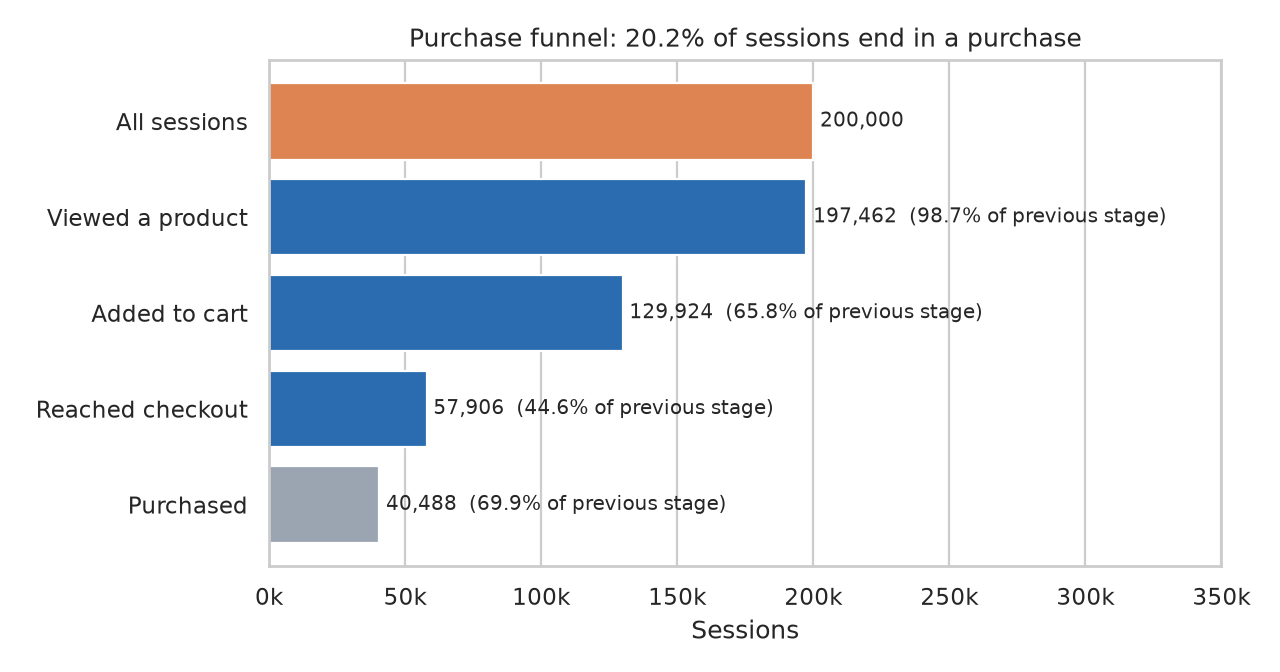

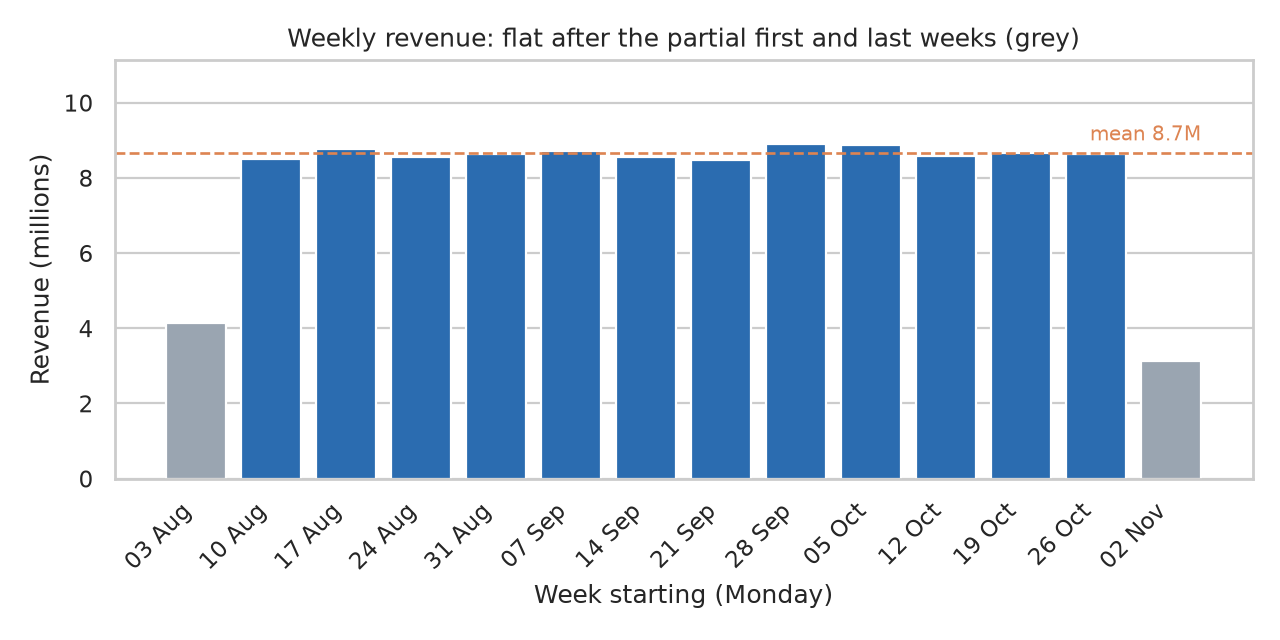

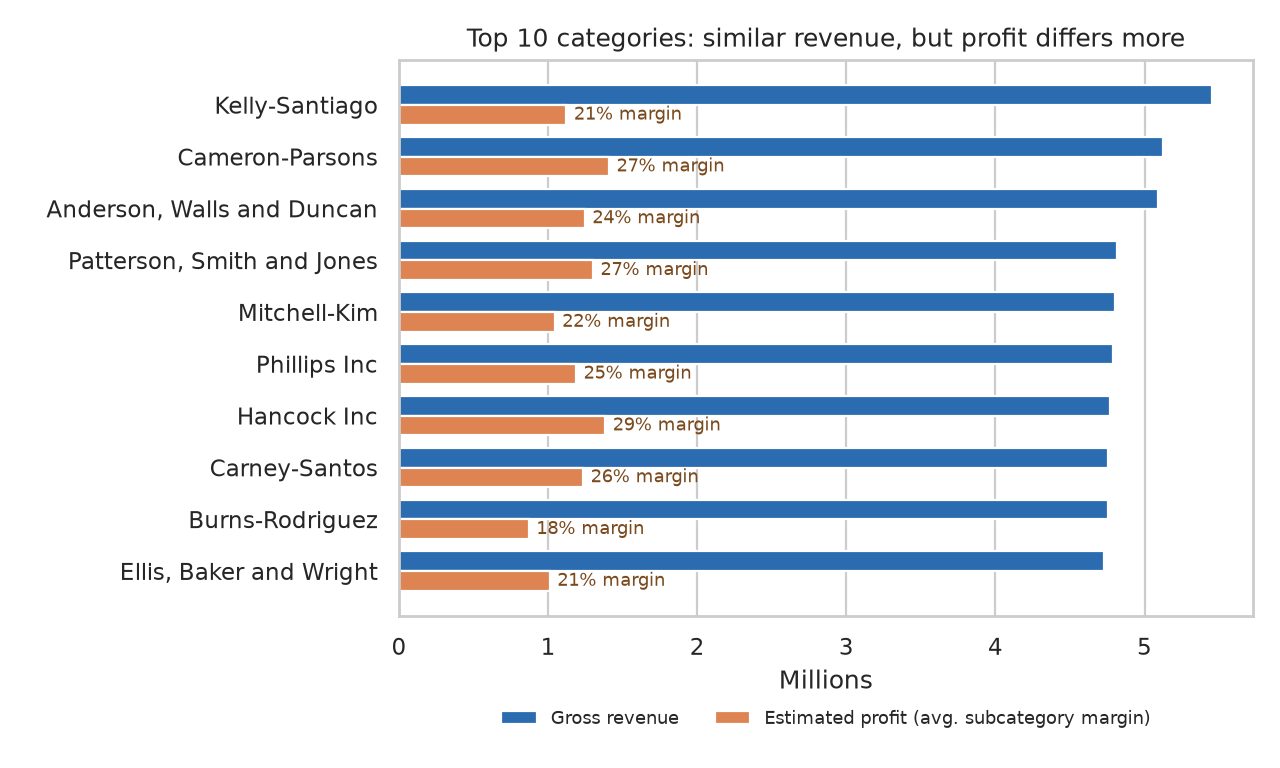

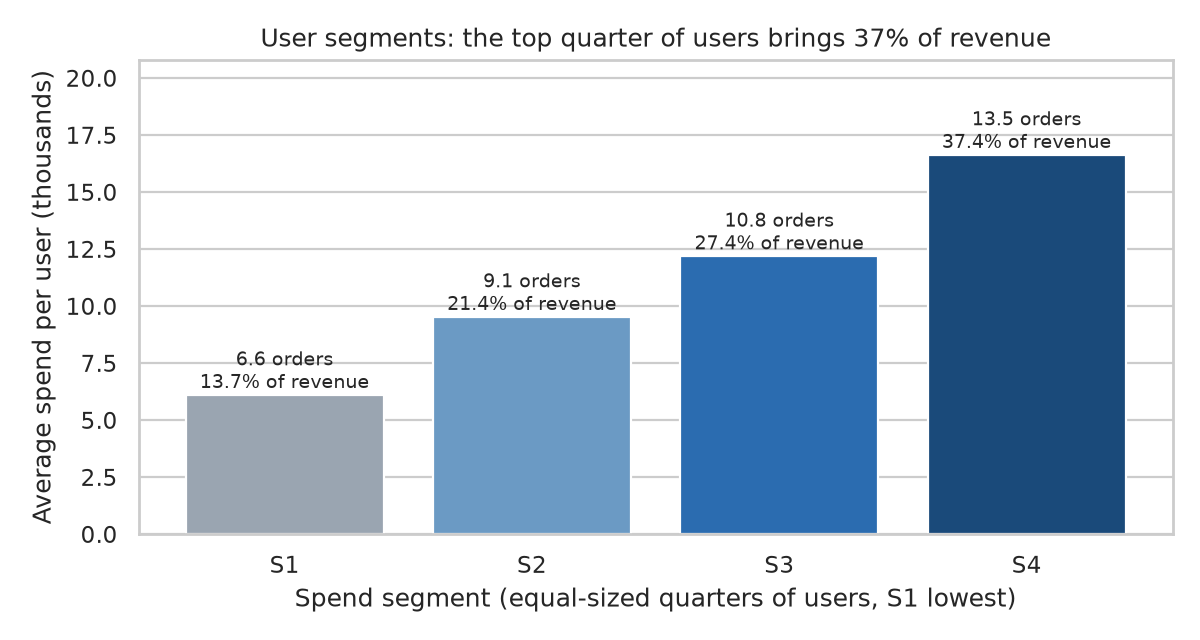

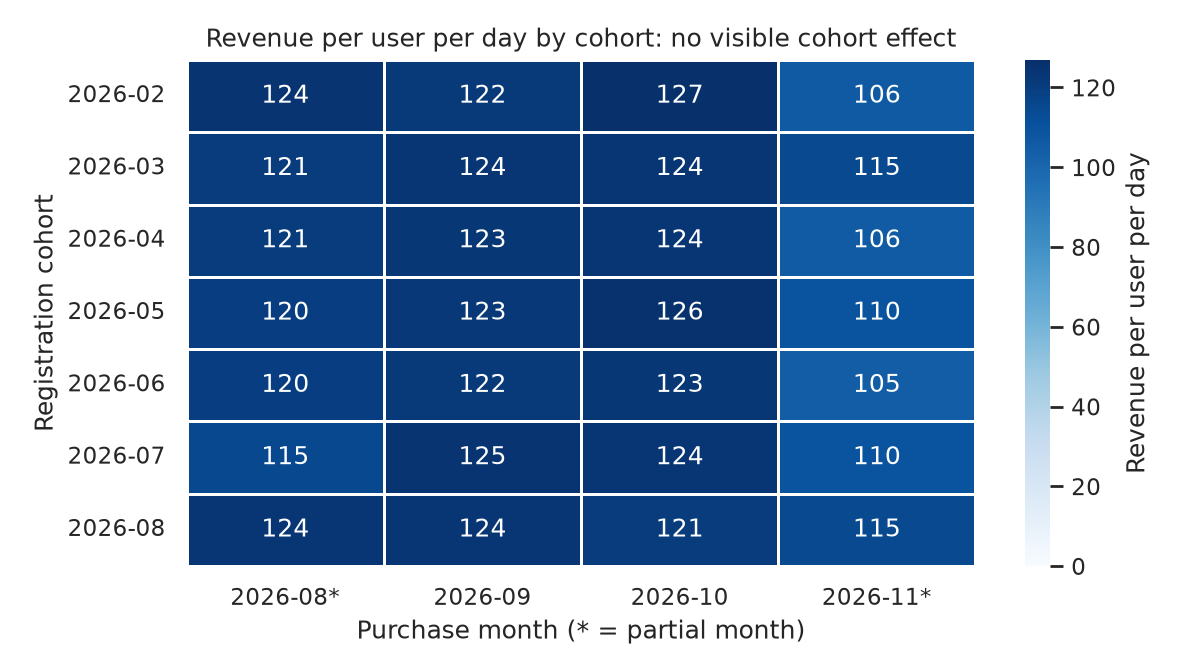

In [22]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("/home/jovyan/work/figures/*.png")):
    display(Image(f, width=600))